Pricing Analytics.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'

FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(exist_ok=True)

from google.colab import files

print("Upload listings_with_occupancy.csv")
up = files.upload()
df = pd.read_csv('listings_with_occupancy.csv', low_memory=False)

# Identify borough column
borough_col = 'neighbourhood_group_cleansed' if (
    'neighbourhood_group_cleansed' in df.columns
    and df['neighbourhood_group_cleansed'].notna().sum() > 0
) else 'neighbourhood_cleansed'

# Keep only rows with valid price and occupancy
df = df[df['price'].notna() & (df['price'] > 0) &
        df['occupancy_rate'].notna()].copy()

print(f"Listings with valid price & occupancy: {len(df):,}")
print(f"Borough column: {borough_col}")


Upload listings_with_occupancy.csv


Saving listings_with_occupancy.csv to listings_with_occupancy.csv
Listings with valid price & occupancy: 59,810
Borough column: neighbourhood_cleansed


Price distribution overview

PRICE DISTRIBUTION OVERVIEW
  10th percentile : £64
  25th percentile : £99
  50th percentile : £175
  75th percentile : £279
  90th percentile : £442
  95th percentile : £597
  99th percentile : £1,184


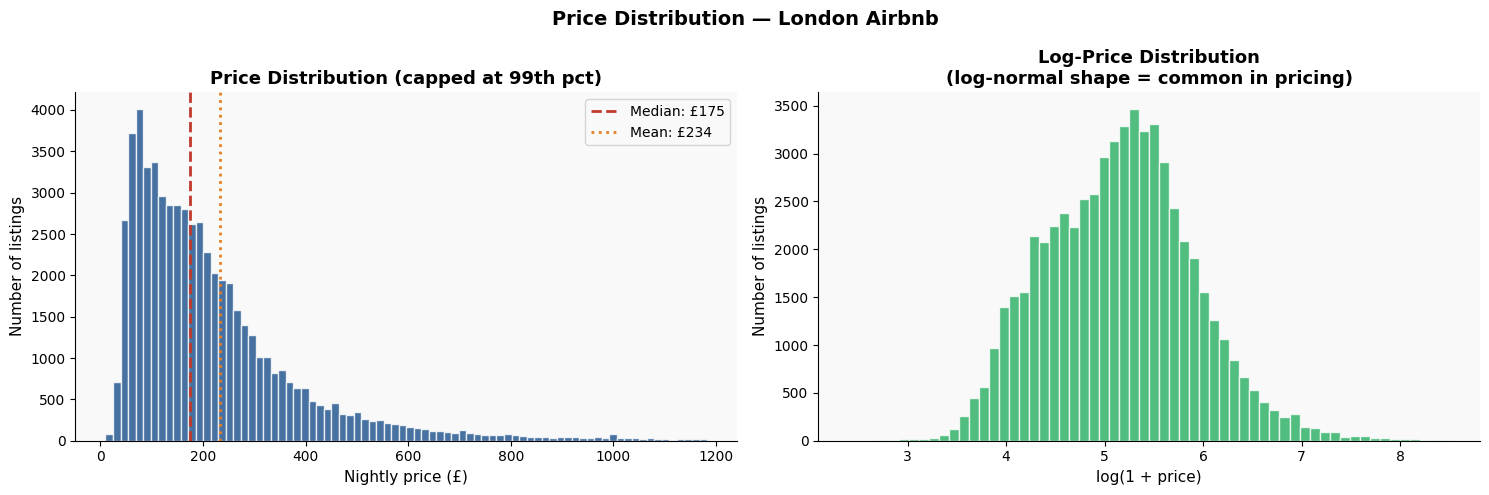

In [3]:
print("=" * 65)
print("PRICE DISTRIBUTION OVERVIEW")
print("=" * 65)

for pct in [10, 25, 50, 75, 90, 95, 99]:
    val = df['price'].quantile(pct / 100)
    print(f"  {pct}th percentile : £{val:,.0f}")

# Remove extreme outliers for visualisation (keep below 99th pct)
p99 = df['price'].quantile(0.99)
df_plot = df[df['price'] <= p99].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Price Distribution — London Airbnb', fontsize=14, fontweight='bold')

axes[0].hist(df_plot['price'], bins=80, color=BLUE, alpha=0.8,
             edgecolor='white', lw=0.3)
axes[0].axvline(df['price'].median(), color=RED, lw=2, linestyle='--',
                label=f"Median: £{df['price'].median():.0f}")
axes[0].axvline(df['price'].mean(), color=ORANGE, lw=2, linestyle=':',
                label=f"Mean: £{df['price'].mean():.0f}")
axes[0].set_title('Price Distribution (capped at 99th pct)', fontweight='bold')
axes[0].set_xlabel('Nightly price (£)')
axes[0].set_ylabel('Number of listings')
axes[0].legend()

axes[1].hist(np.log1p(df['price']), bins=60, color=GREEN, alpha=0.8,
             edgecolor='white', lw=0.3)
axes[1].set_title('Log-Price Distribution\n(log-normal shape = common in pricing)', fontweight='bold')
axes[1].set_xlabel('log(1 + price)')
axes[1].set_ylabel('Number of listings')

plt.tight_layout()
plt.savefig(FIGURES / '11_price_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


Price by room type and Borough

Median price by room type:
      room_type  median       mean  count
Entire home/apt  226.67 294.553117  40447
     Hotel room  187.50 263.236866    134
   Private room   80.00 106.430126  19064
    Shared room   36.00  74.319576    165



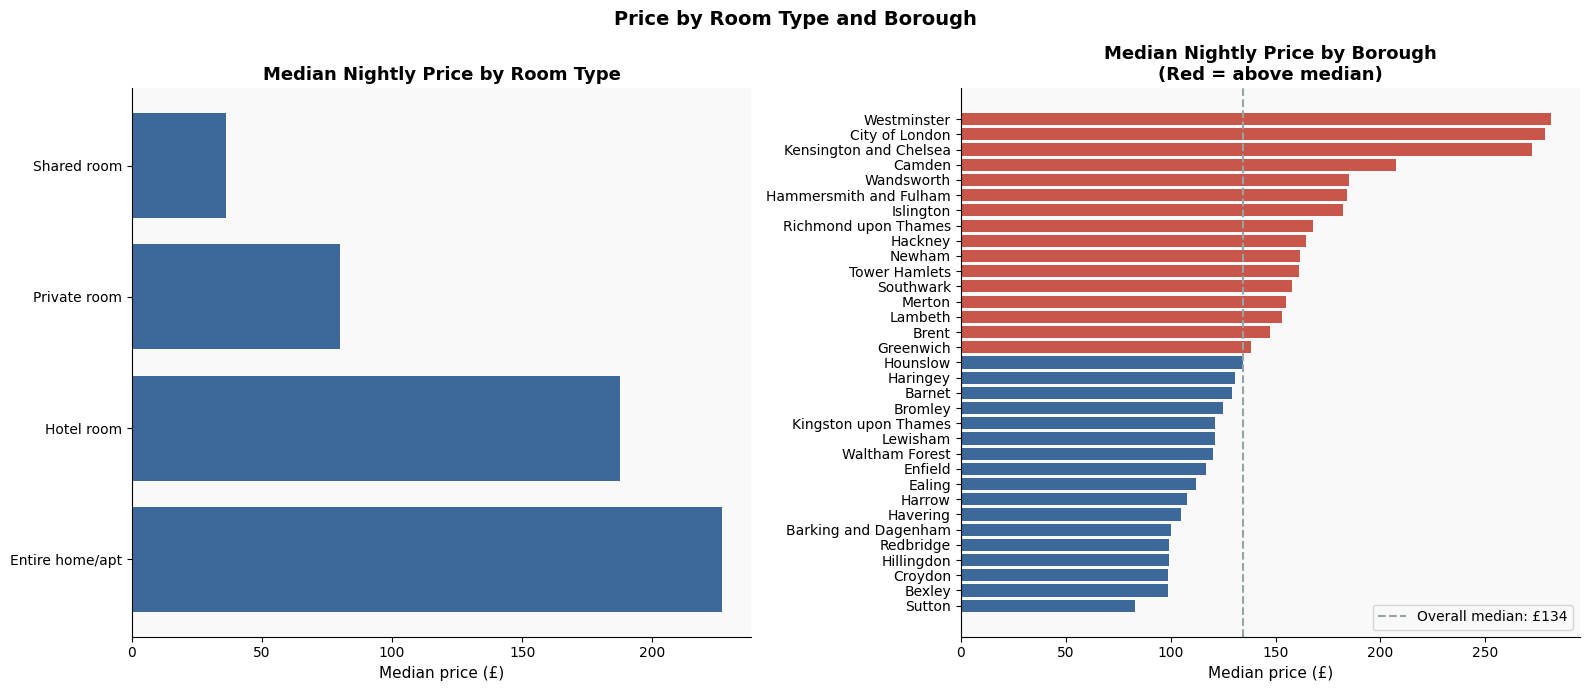

In [4]:
room_price = (df.groupby('room_type')['price']
              .agg(['median', 'mean', 'count'])
              .reset_index()
              .sort_values('median', ascending=False))

print("Median price by room type:")
print(room_price.to_string(index=False))
print()

borough_price = (df.groupby(borough_col)['price']
                 .median()
                 .sort_values(ascending=True))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Price by Room Type and Borough', fontsize=14, fontweight='bold')

axes[0].barh(room_price['room_type'], room_price['median'],
             color=BLUE, alpha=0.85)
axes[0].set_title('Median Nightly Price by Room Type', fontweight='bold')
axes[0].set_xlabel('Median price (£)')

colors_b = [RED if v > borough_price.median() else BLUE for v in borough_price.values]
axes[1].barh(borough_price.index, borough_price.values, color=colors_b, alpha=0.85)
axes[1].axvline(borough_price.median(), color=GREY, lw=1.5, linestyle='--',
                label=f'Overall median: £{borough_price.median():.0f}')
axes[1].set_title('Median Nightly Price by Borough\n(Red = above median)', fontweight='bold')
axes[1].set_xlabel('Median price (£)')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES / '12_price_by_segment.png', dpi=150, bbox_inches='tight')
plt.show()


Price vs occupancy: elasticity analysis

PRICE-OCCUPANCY RELATIONSHIP (PRICE ELASTICITY PROXY)

Price elasticity of demand = % change in occupancy / % change in price
A negative relationship is expected: higher price → lower occupancy.
We estimate this using log-log OLS regression:
  log(occupancy) = β0 + β1 * log(price)
  β1 ≈ price elasticity of demand

Price elasticity estimate (β1): -0.027
R²                            : 0.000

Interpretation: a 10% increase in price is associated with a 0.3% decrease in occupancy.


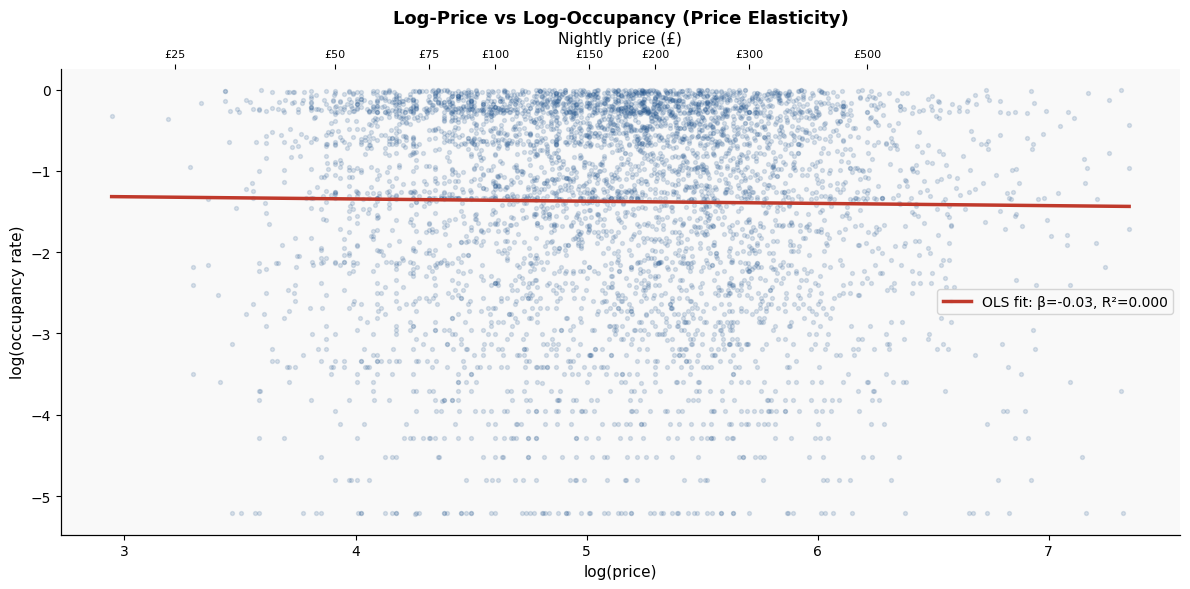

In [5]:
print("=" * 65)
print("PRICE-OCCUPANCY RELATIONSHIP (PRICE ELASTICITY PROXY)")
print("=" * 65)
print("""
Price elasticity of demand = % change in occupancy / % change in price
A negative relationship is expected: higher price → lower occupancy.
We estimate this using log-log OLS regression:
  log(occupancy) = β0 + β1 * log(price)
  β1 ≈ price elasticity of demand
""")

# Log-log regression — use a clean subset
reg_df = df[['price', 'occupancy_rate', 'room_type', borough_col]].dropna().copy()
reg_df = reg_df[(reg_df['price'] > 0) & (reg_df['occupancy_rate'] > 0)]
reg_df['log_price']     = np.log(reg_df['price'])
reg_df['log_occupancy'] = np.log(reg_df['occupancy_rate'])

# Remove extreme outliers (z-score > 3)
reg_df = reg_df[(np.abs(stats.zscore(reg_df[['log_price', 'log_occupancy']])) < 3).all(axis=1)]

X = reg_df[['log_price']].values
y = reg_df['log_occupancy'].values

model = LinearRegression().fit(X, y)
r2    = model.score(X, y)
beta1 = model.coef_[0]

print(f"Price elasticity estimate (β1): {beta1:.3f}")
print(f"R²                            : {r2:.3f}")
print()
print(f"Interpretation: a 10% increase in price is associated with a "
      f"{abs(beta1)*10:.1f}% {'decrease' if beta1 < 0 else 'increase'} in occupancy.")

# Scatter with regression line
fig, ax = plt.subplots(figsize=(12, 6))

sample = reg_df.sample(min(5000, len(reg_df)), random_state=42)
ax.scatter(sample['log_price'], sample['log_occupancy'],
           alpha=0.15, s=8, color=BLUE)

x_line = np.linspace(reg_df['log_price'].min(), reg_df['log_price'].max(), 200)
y_line = model.predict(x_line.reshape(-1, 1))
ax.plot(x_line, y_line, color=RED, lw=2.5,
        label=f'OLS fit: β={beta1:.2f}, R²={r2:.3f}')

ax.set_title('Log-Price vs Log-Occupancy (Price Elasticity)',
             fontweight='bold')
ax.set_xlabel('log(price)')
ax.set_ylabel('log(occupancy rate)')
ax.legend()

# Add price reference ticks
price_ticks = [25, 50, 75, 100, 150, 200, 300, 500]
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks([np.log(p) for p in price_ticks if
                reg_df['log_price'].min() <= np.log(p) <= reg_df['log_price'].max()])
ax2.set_xticklabels([f'£{p}' for p in price_ticks if
                     reg_df['log_price'].min() <= np.log(p) <= reg_df['log_price'].max()],
                    fontsize=8)
ax2.set_xlabel('Nightly price (£)')

plt.tight_layout()
plt.savefig(FIGURES / '13_price_elasticity.png', dpi=150, bbox_inches='tight')
plt.show()


Elasticity by room type

Price Elasticity by Room Type:
      room_type  elasticity    r2  n_listings
   Private room      -0.134 0.003       16903
Entire home/apt      -0.123 0.003       37250
    Shared room       0.553 0.061         126
     Hotel room       0.802 0.158         113


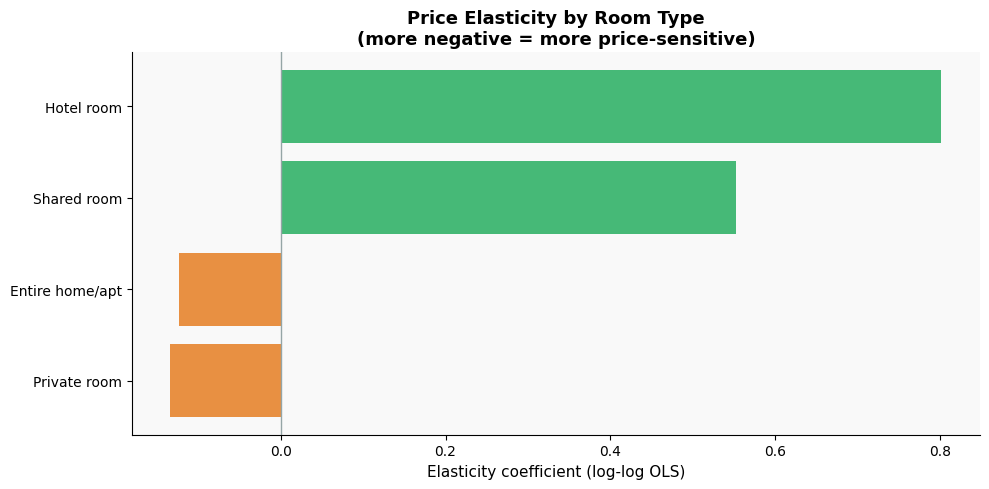

In [6]:
elasticity_by_type = []

for rtype, grp in reg_df.groupby('room_type'):
    if len(grp) < 50:
        continue
    m = LinearRegression().fit(grp[['log_price']], grp['log_occupancy'])
    elasticity_by_type.append({
        'room_type':   rtype,
        'elasticity':  round(m.coef_[0], 3),
        'r2':          round(m.score(grp[['log_price']], grp['log_occupancy']), 3),
        'n_listings':  len(grp),
    })

elas_df = pd.DataFrame(elasticity_by_type).sort_values('elasticity')

print("Price Elasticity by Room Type:")
print(elas_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
colors_e = [RED if v < -0.3 else ORANGE if v < 0 else GREEN for v in elas_df['elasticity']]
ax.barh(elas_df['room_type'], elas_df['elasticity'], color=colors_e, alpha=0.85)
ax.axvline(0, color=GREY, lw=1)
ax.set_title('Price Elasticity by Room Type\n(more negative = more price-sensitive)',
             fontweight='bold')
ax.set_xlabel('Elasticity coefficient (log-log OLS)')
plt.tight_layout()
plt.savefig(FIGURES / '14_elasticity_by_room_type.png', dpi=150, bbox_inches='tight')
plt.show()

elas_df.to_csv(PROCESSED / 'price_elasticity.csv', index=False)


Revenue-maximising price curve

REVENUE-MAXIMISING PRICE

Estimated revenue = price × occupancy_rate
Using the fitted elasticity: occupancy(p) = exp(β0) × p^β1
Optimal price: d/dp [p × occ(p)] = 0 → p* = β0 / (1 + β1)
(only valid when β1 < -1, i.e. elastic demand)

Estimated revenue-maximising price : £500/night
Predicted occupancy at that price  : 24.5%
Predicted nightly revenue          : £123

Note: this is a market-wide average. Optimal price varies by
room type, neighbourhood, and listing quality.


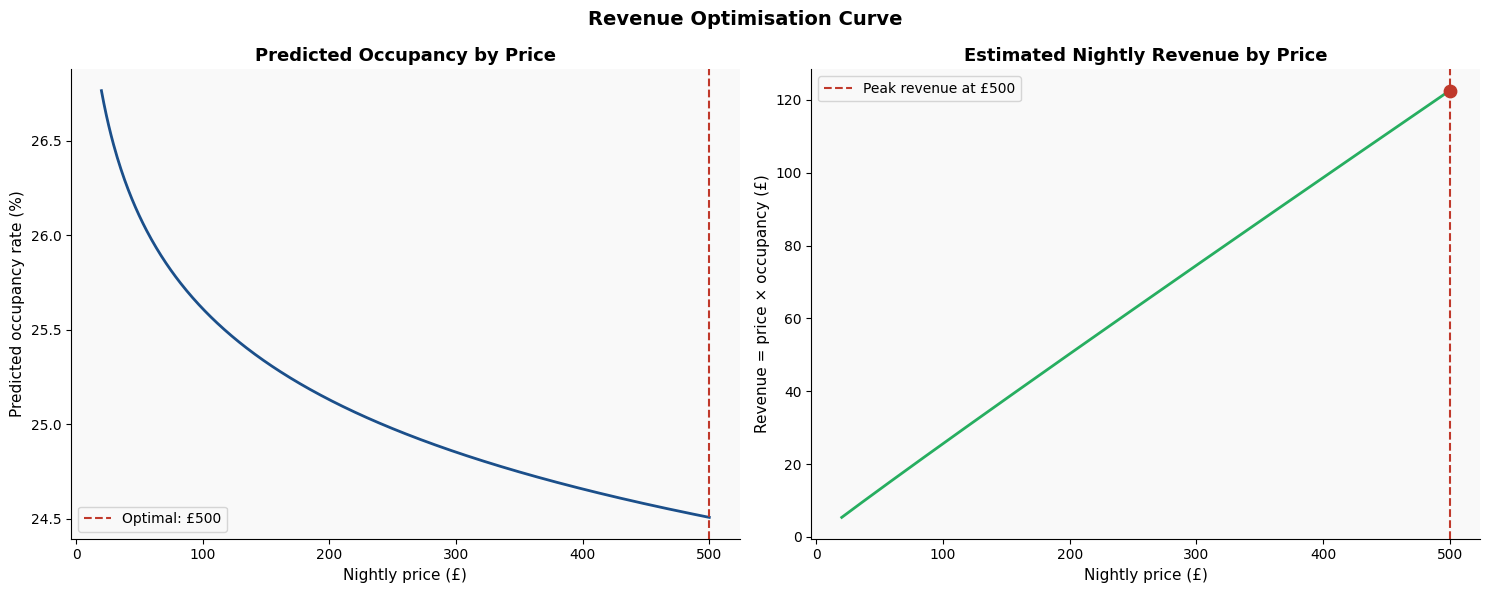

In [7]:
print("=" * 65)
print("REVENUE-MAXIMISING PRICE")
print("=" * 65)
print("""
Estimated revenue = price × occupancy_rate
Using the fitted elasticity: occupancy(p) = exp(β0) × p^β1
Optimal price: d/dp [p × occ(p)] = 0 → p* = β0 / (1 + β1)
(only valid when β1 < -1, i.e. elastic demand)
""")

beta0 = model.intercept_
beta1_val = model.coef_[0]

price_range = np.linspace(20, 500, 500)
log_occ_hat = beta0 + beta1_val * np.log(price_range)
occ_hat     = np.exp(log_occ_hat).clip(0, 1)
rev_hat     = price_range * occ_hat

optimal_idx   = np.argmax(rev_hat)
optimal_price = price_range[optimal_idx]
optimal_occ   = occ_hat[optimal_idx]
optimal_rev   = rev_hat[optimal_idx]

print(f"Estimated revenue-maximising price : £{optimal_price:.0f}/night")
print(f"Predicted occupancy at that price  : {optimal_occ*100:.1f}%")
print(f"Predicted nightly revenue          : £{optimal_rev:.0f}")
print()
print(f"Note: this is a market-wide average. Optimal price varies by")
print(f"room type, neighbourhood, and listing quality.")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Revenue Optimisation Curve', fontsize=14, fontweight='bold')

axes[0].plot(price_range, occ_hat * 100, color=BLUE, lw=2)
axes[0].axvline(optimal_price, color=RED, lw=1.5, linestyle='--',
                label=f'Optimal: £{optimal_price:.0f}')
axes[0].set_title('Predicted Occupancy by Price', fontweight='bold')
axes[0].set_xlabel('Nightly price (£)')
axes[0].set_ylabel('Predicted occupancy rate (%)')
axes[0].legend()

axes[1].plot(price_range, rev_hat, color=GREEN, lw=2)
axes[1].axvline(optimal_price, color=RED, lw=1.5, linestyle='--',
                label=f'Peak revenue at £{optimal_price:.0f}')
axes[1].scatter([optimal_price], [optimal_rev], color=RED, zorder=5, s=80)
axes[1].set_title('Estimated Nightly Revenue by Price', fontweight='bold')
axes[1].set_xlabel('Nightly price (£)')
axes[1].set_ylabel('Revenue = price × occupancy (£)')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES / '15_revenue_optimisation.png', dpi=150, bbox_inches='tight')
plt.show()


Competitive pricing: listings vs borough median

Price position relative to segment median:
  Very cheap (<70%)        : 12,838  (21.5%)
  Cheap (70–90%)           : 11,655  (19.5%)
  At market (90–110%)      : 10,164  (17.0%)
  Premium (110–130%)       :  7,461  (12.5%)
  Luxury (>130%)           : 17,692  (29.6%)


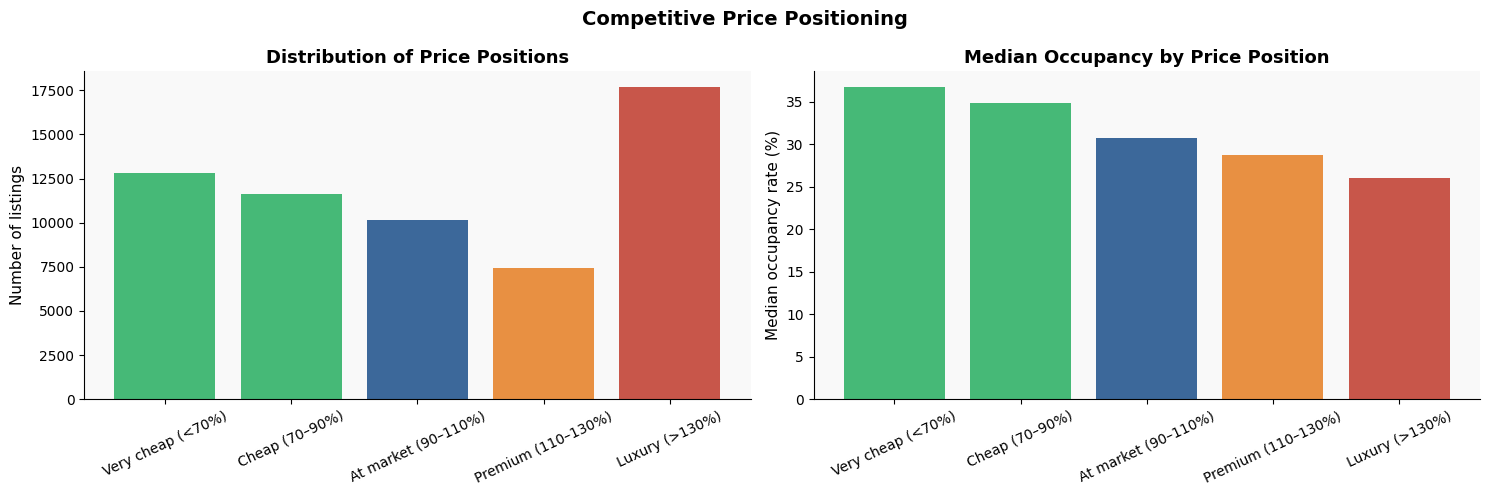

In [8]:
# How does each listing's price compare to the median in its borough × room type segment?
segment_median = (df.groupby([borough_col, 'room_type'])['price']
                  .median()
                  .reset_index()
                  .rename(columns={'price': 'segment_median_price'}))

df = df.merge(segment_median, on=[borough_col, 'room_type'], how='left')
df['price_ratio'] = df['price'] / df['segment_median_price'].replace(0, np.nan)

# Classify competitive position
df['price_position'] = pd.cut(
    df['price_ratio'],
    bins=[0, 0.7, 0.9, 1.1, 1.3, np.inf],
    labels=['Very cheap (<70%)', 'Cheap (70–90%)', 'At market (90–110%)',
            'Premium (110–130%)', 'Luxury (>130%)']
)

pos_counts = df['price_position'].value_counts().sort_index()
print("Price position relative to segment median:")
for pos, count in pos_counts.items():
    pct = count / len(df) * 100
    print(f"  {pos:<25}: {count:>6,}  ({pct:.1f}%)")

# Occupancy by price position
pos_occ = (df.groupby('price_position', observed=True)['occupancy_rate']
           .median().reset_index())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Competitive Price Positioning', fontsize=14, fontweight='bold')

colors_pos = [GREEN, GREEN, BLUE, ORANGE, RED]
axes[0].bar(pos_counts.index, pos_counts.values, color=colors_pos, alpha=0.85)
axes[0].set_title('Distribution of Price Positions', fontweight='bold')
axes[0].set_ylabel('Number of listings')
axes[0].tick_params(axis='x', rotation=25)

axes[1].bar(pos_occ['price_position'], pos_occ['occupancy_rate'] * 100,
            color=colors_pos[:len(pos_occ)], alpha=0.85)
axes[1].set_title('Median Occupancy by Price Position', fontweight='bold')
axes[1].set_ylabel('Median occupancy rate (%)')
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.savefig(FIGURES / '16_competitive_pricing.png', dpi=150, bbox_inches='tight')
plt.show()

df[['id', borough_col, 'room_type', 'price', 'occupancy_rate',
    'segment_median_price', 'price_ratio', 'price_position']].to_csv(
    PROCESSED / 'pricing_analysis.csv', index=False)


Weekend and seasonal pricing premium

Upload demand_by_dow.csv


Saving demand_by_dow.csv to demand_by_dow.csv
Upload demand_by_month.csv


Saving demand_by_month.csv to demand_by_month.csv
Upload seasonal_index.csv


Saving seasonal_index.csv to seasonal_index.csv

Weekend occupancy  : 58.2%
Weekday occupancy  : 57.4%
Weekend premium    : +1.3%

Peak month         : Jul  (index: 1.46x average demand)
Trough month       : Feb  (index: 0.68x average demand)
Seasonal swing     : 0.78x — a host should charge 78% more in peak vs trough to maintain revenue


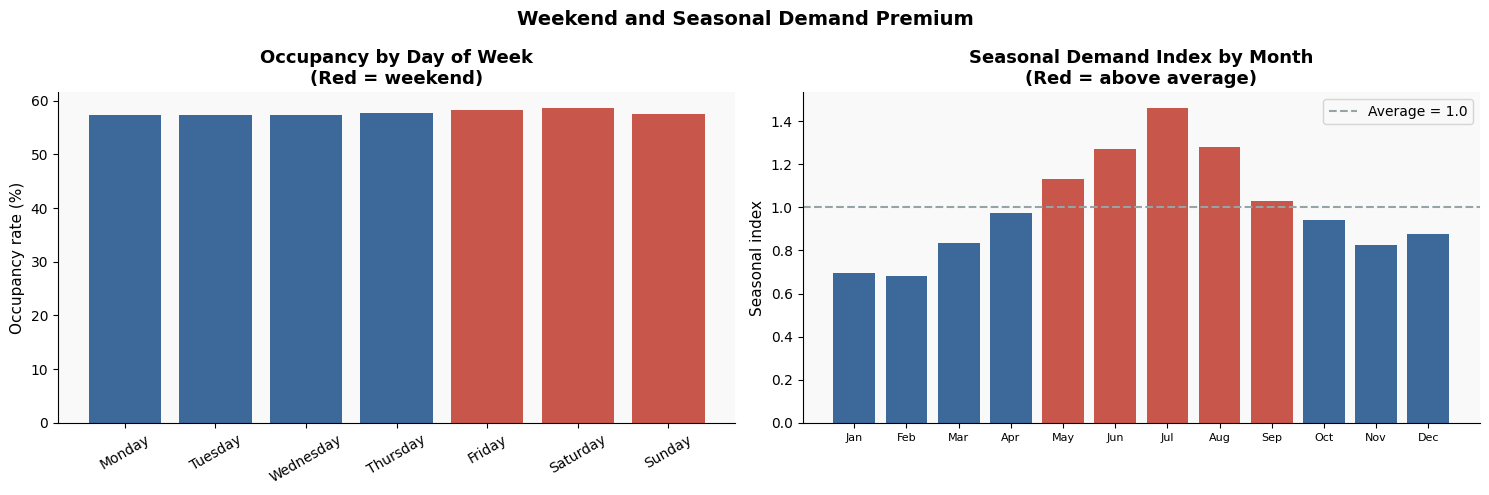

In [9]:
print("Upload demand_by_dow.csv")
up_dow = files.upload()
print("Upload demand_by_month.csv")
up_mon = files.upload()
print("Upload seasonal_index.csv")
up_si  = files.upload()

dow_stats      = pd.read_csv('demand_by_dow.csv')
monthly_stats  = pd.read_csv('demand_by_month.csv')
seasonal_index = pd.read_csv('seasonal_index.csv')

month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

weekend_occ  = dow_stats[dow_stats['day_of_week'].isin(['Friday','Saturday','Sunday'])]['occupancy'].mean()
weekday_occ  = dow_stats[~dow_stats['day_of_week'].isin(['Friday','Saturday','Sunday'])]['occupancy'].mean()
weekend_prem = (weekend_occ - weekday_occ) / weekday_occ * 100 if weekday_occ > 0 else 0

peak_idx    = seasonal_index['seasonal_index'].max()
trough_idx  = seasonal_index['seasonal_index'].min()
peak_month  = month_names[seasonal_index['seasonal_index'].idxmax()]
trough_month= month_names[seasonal_index['seasonal_index'].idxmin()]

print(f"\nWeekend occupancy  : {weekend_occ*100:.1f}%")
print(f"Weekday occupancy  : {weekday_occ*100:.1f}%")
print(f"Weekend premium    : +{weekend_prem:.1f}%")
print()
print(f"Peak month         : {peak_month}  (index: {peak_idx:.2f}x average demand)")
print(f"Trough month       : {trough_month}  (index: {trough_idx:.2f}x average demand)")
print(f"Seasonal swing     : {(peak_idx - trough_idx):.2f}x — a host should charge "
      f"{(peak_idx - trough_idx)*100:.0f}% more in peak vs trough to maintain revenue")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Weekend and Seasonal Demand Premium', fontsize=14, fontweight='bold')

dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow_stats_ord = dow_stats.set_index('day_of_week').reindex(dow_order).reset_index()
axes[0].bar(dow_stats_ord['day_of_week'], dow_stats_ord['occupancy'] * 100,
            color=[RED if d in ['Friday','Saturday','Sunday'] else BLUE
                   for d in dow_stats_ord['day_of_week']],
            alpha=0.85)
axes[0].set_title('Occupancy by Day of Week\n(Red = weekend)', fontweight='bold')
axes[0].set_ylabel('Occupancy rate (%)')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(seasonal_index['month'], seasonal_index['seasonal_index'],
            color=[RED if v > 1 else BLUE for v in seasonal_index['seasonal_index']],
            alpha=0.85)
axes[1].axhline(1.0, color=GREY, lw=1.5, linestyle='--', label='Average = 1.0')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names, fontsize=8)
axes[1].set_title('Seasonal Demand Index by Month\n(Red = above average)', fontweight='bold')
axes[1].set_ylabel('Seasonal index')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES / '17_weekend_seasonal_premium.png', dpi=150, bbox_inches='tight')
plt.show()


Summary pricing insights table

In [10]:
borough_summary = (df.groupby(borough_col)
                   .agg(
                       listings=('id', 'count'),
                       median_price=('price', 'median'),
                       median_occupancy=('occupancy_rate', 'median'),
                       pct_premium=('price_position',
                                    lambda x: (x.isin(['Premium (110–130%)',
                                                        'Luxury (>130%)'])).mean() * 100),
                   )
                   .reset_index()
                   .sort_values('median_price', ascending=False))

borough_summary['est_monthly_revenue'] = (
    borough_summary['median_price'] *
    borough_summary['median_occupancy'] * 30
)

print("Borough Pricing Summary:")
print(borough_summary.to_string(index=False))

borough_summary.to_csv(PROCESSED / 'borough_pricing_summary.csv', index=False)


Borough Pricing Summary:
neighbourhood_cleansed  listings  median_price  median_occupancy  pct_premium  est_monthly_revenue
           Westminster      7931       281.000          0.276712    43.891060          2332.684932
        City of London       502       278.250          0.135616    44.422311          1132.058219
Kensington and Chelsea      4644       272.250          0.347945    44.724376          2841.842466
                Camden      4288       207.500          0.312329    42.164179          1944.246575
            Wandsworth      2689       185.090          0.339726    41.799926          1886.396712
Hammersmith and Fulham      2678       184.000          0.342466    41.411501          1890.410959
             Islington      2495       182.000          0.367123    42.044088          2004.493151
  Richmond upon Thames       762       167.785          0.434247    42.388451          2185.801849
               Hackney      2825       164.330          0.402740    40.176991       

In [12]:
import shutil

print("Saved files:")
for f in sorted(PROCESSED.glob('*.csv')):
    print(f"  {f.name:<55}  {f.stat().st_size/1024:6.1f} KB")

shutil.make_archive('/content/marketiq_nb03', 'zip', '/content')
files.download('/content/marketiq_nb03.zip')
print("\nDownloaded marketiq_nb03.zip")


Saved files:
  borough_pricing_summary.csv                                 2.6 KB
  price_elasticity.csv                                        0.2 KB
  pricing_analysis.csv                                     6415.7 KB


RuntimeError: File size too large, try using force_zip64